# 301 – Building a Custom Quantum Algorithm: Hamiltonian Evolution Fidelity

In this notebook you will **write your own quantum algorithm as a Python class** and use it to answer a physics question:

> *How accurately can a quantum circuit simulate the time evolution of a quantum system?*

**What you will learn**
1. What time evolution $e^{-iHt}$ means and why it is at the heart of quantum simulation.
2. How a Hamiltonian is written as a weighted sum of Pauli operators.
3. How the **Trotter–Suzuki** product formula turns $e^{-iHt}$ into a circuit of ordinary gates.
4. How to score a simulation with the **state fidelity**.
5. How to package all of this as a reusable algorithm class with a `run(backend)` method.

**Where this example comes from.** It started as the "build your own algorithm" tutorial of **Qiskit Aqua**, where every algorithm extended Aqua's `QuantumAlgorithm` base class. Aqua was removed from Qiskit in 2021; today an algorithm is an ordinary Python class built from Qiskit's circuit library (`PauliEvolutionGate`, `SuzukiTrotter`, …). The idea of the tutorial is unchanged.

**Related notebooks**
- `101-VariationalForms-TwoLocal.ipynb` – also uses `PauliEvolutionGate` and `SuzukiTrotter`.
- `002-QuantumCircuits-006-SwapTest.ipynb` – how the overlap of two states can be measured on real hardware.

## Step 1 – Choose a backend

A **backend** is whatever runs our circuits: a local simulator or real IBM quantum hardware. The helper module `qiskit_backend_config.py` (in this folder) hides the differences between Qiskit versions and gives us `get_backend()` and `execute()`.

We use the **`statevector_simulator`**. Instead of measurement counts it returns the complete final quantum state $|\psi\rangle$, i.e. all $2^n$ complex amplitudes. That lets us compare the circuit's output *exactly* with the mathematically correct answer. Real hardware only returns measurement samples, so it cannot be used for this exact comparison.

In [1]:
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import get_backend, execute

# The statevector simulator returns the full final quantum state (no measurements needed)
BACKEND_NAME = "statevector_simulator"

backend = get_backend(BACKEND_NAME)
print(f'Backend ready: {backend}')

Backend ready: LegacyAerSimulator('aer_simulator_statevector')


## Step 2 – Import the tools

| Import | What it is used for |
|---|---|
| `numpy` | arrays and random numbers |
| `scipy.linalg.expm` | the *exact* matrix exponential $e^{-iHt}$ – our "ground truth" |
| `QuantumCircuit`, `transpile` | building circuits and rewriting them into basic gates |
| `SparsePauliOp` | a Hamiltonian stored as a weighted sum of Pauli strings |
| `Operator`, `Statevector` | exact matrices and quantum states from `qiskit.quantum_info` |
| `state_fidelity` | how close two quantum states are |
| `PauliEvolutionGate` | a single gate that stands for $e^{-iHt}$ |
| `SuzukiTrotter` | the recipe that expands that gate into ordinary one- and two-qubit gates |

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import Operator, SparsePauliOp, Statevector, state_fidelity
from qiskit.synthesis import SuzukiTrotter

## Background – time evolution and the Trotter–Suzuki formula

**Time evolution.** A closed quantum system with Hamiltonian $H$ (its energy operator) evolves according to the Schrödinger equation, whose solution is

$$|\psi(t)\rangle = e^{-iHt}\,|\psi(0)\rangle .$$

Simulating this is one of the most promising uses of quantum computers (chemistry, materials, …): the matrix $e^{-iHt}$ has size $2^n \times 2^n$, which quickly becomes too large for any classical computer.

**Pauli decomposition.** Every $n$-qubit Hamiltonian can be written as a weighted sum of Pauli strings

$$H = \sum_j c_j P_j, \qquad P_j \in \{I, X, Y, Z\}^{\otimes n}, \quad c_j \in \mathbb{R}.$$

For a *single* Pauli string, $e^{-i c_j t P_j}$ is easy to build: a few basis changes, a ladder of CNOTs and one $R_z$ rotation.

**The catch.** Pauli terms usually do **not commute** ($AB \ne BA$), and then $e^{-i(A+B)t} \ne e^{-iAt}e^{-iBt}$. We cannot simply apply the terms one after another.

**Trotter–Suzuki product formulas.** Split the time $t$ into $r$ small steps (`reps`). For short steps the error becomes small:

- 1st order (Lie–Trotter): $e^{-i(A+B)t} \approx \big(e^{-iAt/r}\,e^{-iBt/r}\big)^r$, error $\mathcal{O}(t^2/r)$
- 2nd order (symmetric Suzuki): $e^{-i(A+B)t} \approx \big(e^{-iAt/2r}\,e^{-iBt/r}\,e^{-iAt/2r}\big)^r$, error $\mathcal{O}(t^3/r^2)$
- Higher even orders $2k$ are built recursively from the 2nd-order formula, error $\mathcal{O}(t^{2k+1}/r^{2k})$.

More steps or a higher order give a more accurate circuit, but also a **deeper** one (more gates, hence more noise on real hardware). We will explore this trade-off in Step 6.

**Fidelity.** To score the simulation we compare the circuit's output $|\phi\rangle$ with the exact state $|\psi\rangle$:

$$F = |\langle\psi|\phi\rangle|^2 .$$

$F = 1$ means the states are identical; $F = 0$ means they are orthogonal (completely different).

## Step 3 – Write the algorithm as a class

Packaging an algorithm as a class is good practice – it is how Aqua and today's `qiskit-algorithms` are organised:

- `__init__` stores the **problem** (Hamiltonian and initial state) and the **settings** (time $t$, expansion order, number of Trotter steps).
- `construct_circuit()` builds the quantum circuit: prepare the initial state, then apply the Trotterised evolution.
- `run(backend)` does the work and returns the results as a dictionary.

Inside `run`:
1. **Exact answer (classical).** Compute the matrix $e^{-iHt}$ with `scipy.linalg.expm` and apply it to the initial state. This only works because our system is tiny.
2. **Quantum answer.** `transpile` rewrites the Trotter circuit into the basic gates a quantum computer actually offers ($R_z$, $\sqrt{X}$, $X$, CNOT). We run that circuit on the backend and read back the final statevector.
3. **Score.** Compute the fidelity between the two states, and record the circuit cost: its depth (number of gate layers) and number of CNOTs. CNOTs are the noisiest gates on real hardware, so they are the usual measure of cost.

About `expansion_order`: Aqua's Suzuki expansion of order $k$ is the symmetric formula of order $2k$, so `expansion_order=1` means `SuzukiTrotter(order=2)` and `expansion_order=2` means `SuzukiTrotter(order=4)`.

In [3]:
class EvolutionFidelity:
    """Fidelity between the exact evolution exp(-iHt)|psi0> and its Trotter-Suzuki circuit."""

    def __init__(self, operator, initial_state, evo_time=1.0, expansion_order=1, reps=1):
        self._operator = operator             # Hamiltonian H as a SparsePauliOp
        self._initial_state = initial_state   # QuantumCircuit preparing |psi(0)>
        self._evo_time = evo_time             # evolution time t
        self._expansion_order = expansion_order
        self._reps = reps                     # number of Trotter steps r
        self._ret = {}

    def construct_circuit(self):
        """Initial state followed by the Suzuki expansion of exp(-iHt)."""
        circuit = self._initial_state.copy()
        # Aqua's Suzuki expansion order k is the symmetric formula of order 2k
        synthesis = SuzukiTrotter(order=2 * self._expansion_order, reps=self._reps)
        circuit.append(PauliEvolutionGate(self._operator, time=self._evo_time, synthesis=synthesis),
                       circuit.qubits)
        return circuit

    def run(self, backend):
        # 1. ground truth: apply the exact matrix exp(-iHt) to the initial state
        exact_unitary = Operator(expm(-1j * self._evo_time * self._operator.to_matrix()))
        state_out_exact = Statevector(self._initial_state).evolve(exact_unitary)

        # 2. rewrite the Trotter circuit into basic gates, run it and read back the final statevector
        basic = transpile(self.construct_circuit(), basis_gates=['rz', 'sx', 'x', 'cx'], optimization_level=0)
        result = execute(basic, backend).result()
        state_out_dynamics = Statevector(np.asarray(result.get_statevector(basic)))

        # 3. score the simulation and record what it cost
        self._ret['score'] = state_fidelity(state_out_exact, state_out_dynamics)
        self._ret['depth'] = basic.depth()
        self._ret['cnot_count'] = basic.count_ops().get('cx', 0)
        return self._ret

## Step 4 – Define the problem: a random 2-qubit Hamiltonian

- We draw a random real $4\times4$ matrix `temp`. The sum `temp + temp.T` is **symmetric**, and a real symmetric matrix is Hermitian, so it is a valid Hamiltonian (its energies are real).
- `SparsePauliOp.from_operator` decomposes the matrix into Pauli strings $\sum_j c_j P_j$. For 2 qubits there are at most $4^2 = 16$ strings. Because our matrix is real, strings with an odd number of $Y$s (which are imaginary) never appear.
- The initial state is $|00\rangle$: an empty `QuantumCircuit`, since every qubit starts in $|0\rangle$. Aqua called this the `Zero` initial state.
- A fixed random seed makes the results reproducible. Change it to try other Hamiltonians.

In [4]:
rng = np.random.default_rng(seed=42)   # fixed seed -> same Hamiltonian every run
num_qubits = 2

temp = rng.random((2 ** num_qubits, 2 ** num_qubits))
hamiltonian_matrix = temp + temp.T            # real symmetric => Hermitian
qubit_op = SparsePauliOp.from_operator(Operator(hamiltonian_matrix))

print(f'H is a sum of {len(qubit_op)} Pauli terms:')
for pauli, coeff in zip(qubit_op.paulis, qubit_op.coeffs):
    print(f'  {coeff.real:+.4f} * {pauli}')

initial_state = QuantumCircuit(num_qubits)    # |00>

H is a sum of 10 Pauli terms:
  +1.1738 * II
  +0.9516 * IX
  -0.0291 * IZ
  +1.2978 * XI
  +1.2764 * XX
  -0.3111 * XZ
  -0.0649 * YY
  +0.5758 * ZI
  -0.4186 * ZX
  -0.1726 * ZZ


## Step 5 – Run the algorithm

We create the algorithm object with evolution time $t = 1$, `expansion_order=1` (2nd-order Suzuki) and a single Trotter step, then call `run`. A fidelity close to 1 means the circuit approximates the true evolution well.

In [5]:
algo = EvolutionFidelity(qubit_op, initial_state, evo_time=1.0, expansion_order=1, reps=1)
result = algo.run(backend)

print(f"Fidelity      : {result['score']:.6f}")
print(f"Circuit depth : {result['depth']}")
print(f"CNOT count    : {result['cnot_count']}")

Fidelity      : 0.988680
Circuit depth : 87
CNOT count    : 18


Let's look at the circuit. At the top level it is just one `PauliEvolutionGate` box. Decomposing it once shows the Suzuki recipe: one small evolution gate per Pauli term, with the outer terms applied for half a time step on each side of the middle one (the symmetric 2nd-order pattern). Each of these small gates is in turn built from CNOTs and an $R_z$ rotation.

In [6]:
circuit = algo.construct_circuit()
print(circuit.draw())
print(circuit.decompose().draw())

     ┌────────────────────────────────────────────────────────────────┐
q_0: ┤0                                                               ├
     │  exp(-it (II + IX + IZ + XI + XX + XZ + YY + ZI + ZX + ZZ))(1) │
q_1: ┤1                                                               ├
     └────────────────────────────────────────────────────────────────┘
global phase: 5.1094
     ┌─────────────┐┌───────────────┐┌──────────────┐┌────────────────┐»
q_0: ┤ Rx(0.95162) ├┤ Rz(-0.029054) ├┤0             ├┤0               ├»
     └┬────────────┤└───────────────┘│  Rxx(1.2764) ││  Rzx(-0.31106) │»
q_1: ─┤ Rx(1.2978) ├─────────────────┤1             ├┤1               ├»
      └────────────┘                 └──────────────┘└────────────────┘»
«     ┌─────────────────┐               ┌────────────────┐               »
«q_0: ┤0                ├───────────────┤1               ├─■─────────────»
«     │  Ryy(-0.064854) │┌─────────────┐│  Rzx(-0.41856) │ │ZZ(-0.34523) »
«q_1: ┤1                ├┤ Rz

## Step 6 – Experiment: accuracy versus circuit cost

Now we repeat the run for several numbers of Trotter steps $r$ and for two orders (2nd and 4th). What to look for:

- The **infidelity** $1 - F$ should shrink as $r$ grows. On a log–log plot the slope shows the order of the method: the infidelity is the *square* of the state error, so it falls roughly like $r^{-4}$ for 2nd order and $r^{-8}$ for 4th order, until it reaches the numerical floor of the computer (about $10^{-15}$).
- The **cost** in CNOTs grows linearly with $r$, and one 4th-order step costs about five 2nd-order steps.

This is the everyday trade-off of quantum simulation: accuracy versus circuit depth (and therefore noise on real hardware).

Suzuki order 2:
  reps =  1   1 - F = 1.13e-02   CNOTs = 18
  reps =  2   1 - F = 4.01e-04   CNOTs = 36
  reps =  4   1 - F = 2.31e-05   CNOTs = 72
  reps =  8   1 - F = 1.42e-06   CNOTs = 144
  reps = 16   1 - F = 8.83e-08   CNOTs = 288
Suzuki order 4:
  reps =  1   1 - F = 1.40e-04   CNOTs = 90
  reps =  2   1 - F = 1.10e-07   CNOTs = 180
  reps =  4   1 - F = 3.41e-10   CNOTs = 360
  reps =  8   1 - F = 9.59e-13   CNOTs = 720
  reps = 16   1 - F = 1.00e-16   CNOTs = 1440


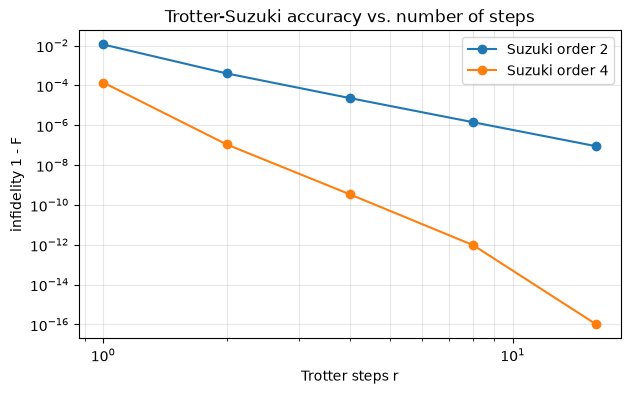

In [7]:
reps_list = [1, 2, 4, 8, 16]

plt.figure(figsize=(7, 4))
for order in (1, 2):
    infidelities, cnots = [], []
    for reps in reps_list:
        res = EvolutionFidelity(qubit_op, initial_state, evo_time=1.0,
                                expansion_order=order, reps=reps).run(backend)
        infidelities.append(max(1 - res['score'], 1e-16))   # avoid log(0) once we hit the floor
        cnots.append(res['cnot_count'])
    print(f'Suzuki order {2 * order}:')
    for reps, inf, cx in zip(reps_list, infidelities, cnots):
        print(f'  reps = {reps:2d}   1 - F = {inf:.2e}   CNOTs = {cx}')
    plt.loglog(reps_list, infidelities, 'o-', label=f'Suzuki order {2 * order}')

plt.xlabel('Trotter steps r')
plt.ylabel('infidelity 1 - F')
plt.title('Trotter-Suzuki accuracy vs. number of steps')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

## Summary

- An algorithm is just a class: the problem and settings go into `__init__`, the work goes into `run(backend)`.
- Time evolution $e^{-iHt}$ cannot be applied directly; the Hamiltonian is split into Pauli terms and approximated with a Trotter–Suzuki product formula.
- The state fidelity tells us how good the approximation is. Higher order and more steps raise the fidelity but cost more gates.

## Exercises

1. Set `evo_time=2.0`. Why does the fidelity drop for the same number of steps?
2. Use `num_qubits = 3`. How do the number of Pauli terms and the CNOT count change?
3. Start from a different initial state, e.g. add `initial_state.h(0)` before running. Does the fidelity change?
4. Try first-order Lie–Trotter: `from qiskit.synthesis import LieTrotter` and use `LieTrotter(reps=...)` in `construct_circuit`. How does its slope in the plot compare?
5. On real hardware we cannot read out the statevector. How could you estimate the fidelity there? (Hint: see the swap test notebook.)